## Machine Learning Week-1 Notebook

### Table of Contents


##### 1. Intro to Machine Learning
##### 2. Supervised Learning & Unsupervised Learning
##### 3. Regression Analysis & Classification Analysis
##### 4. OLS Method
##### 5. Regression Metrics
##### 6. Assumptions
##### 7. Regularization
##### 8. Cross Validation
##### 9. Grid SearchCV
##### 10. Gradient Descent Method


##### What is Machine Learning

Machine Learning is a branch of artificial intelligence which teaches computers/machines to learn from data and make decisions or predictions without being directly told what to do. The computer improves its performance as it gets more data and experience.

##### 1. Supervised Learning

Supervised Learning is a type of machine learning where the model is trained on a labeled dataset, meaning that each training example is paired with an output label.

In short in supervised learning we have Target Varible.

##### Regression Analysis

Regression Analysis is a statistical and machine learning technique used to study the relationship between a dependent variable (target) and one or more independent variables (features).
It helps in predicting a continuous outcome based on input data and understanding how changes in one or more variables affect the target variable.

Dependent variable (y): It is the variable that we predict. It is also known as 'Target' or 'Response' variable. For regression, the dependent variable should be numeric.

Independent variable (X): It is the variable used in predicting the values of a target variable. There can be one or more independent variables in a dataset. It is also known as 'predictors' or 'features'. These variables can be numerical as well as categorical.

Examples:

Predicting house prices using area, number of rooms, and location.

Estimating sales revenue based on advertising spend.

##### Classification Analysis

Classification Analysis is a machine learning technique used to predict a category or class label for given input data.
It helps in dividing data into predefined groups based on patterns learned from labeled examples during training.

In simple words:
Classification is used when we want to predict categories — like yes/no, spam/not spam, or types of animals — instead of numbers.

Examples:

Identifying whether an email is spam or not spam.

Predicting whether a loan applicant will default or not.

##### 2. Unsupervised Learning

Unsupervised Learning is a type of machine learning where the model is trained on an unlabeled dataset. The system tries to identify hidden structures or patterns in the data without predefined output labels, often through techniques like clustering or dimensionality reduction.

In short in supervised learning we dont have Target Varible.

### Regression Analysis

In [ ]:
# Import required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##### We will use Salary dataset

###### Data Dictionary

| **Variable Name** | **Type**             | **Description**                                    | **Example Values**                 |
| ----------------- | -------------------- | -------------------------------------------------- | ---------------------------------- |
| **Salary_Rupees** | *Numerical (Target)* | The employee’s total annual salary (in Rupees).    | 125000, 210000                     |
| **Experience**    | *Numerical*          | Total work experience of the employee in years.    | 5, 12, 25                          |
| **Age**           | *Numerical*          | Age of the employee in years.                      | 28, 35, 50                         |
| **Gender**        | *Categorical*        | Gender of the employee.                            | Male, Female                       |
| **Designation**   | *Categorical*        | Current job position or level in the organization. | Associate, Manager, Senior Manager |
| **Education**     | *Categorical*        | Highest qualification of the employee.             | UG, PG                             |
| **Height_cm**     | *Numerical*          | Employee’s height in centimeters.                  | 160.5, 172.8, 210.3                |
| **Weight_kg**     | *Numerical*          | Employee’s weight in kilograms.                    | 60.2, 85.5, 130.4                  |


In [ ]:
df = pd.read_csv('/content/Salary.csv')
df.head()

,Experience,Age,Gender,Designation,Education,Height_cm,Weight_kg,Salary_Rupees
0,6,37,Female,Associate,UG,161.4,81.8,97634.09
1,19,47,Male,Associate,UG,170.1,61.1,150705.15
2,28,59,Female,Manager,PG,168.2,44.1,221352.13
3,14,38,Male,Associate,PG,164.7,73.1,132014.12
4,10,33,Male,Senior Manager,UG,164.4,81.9,127330.77


##### Model Pre-Processing

###### Before Model Building 2 important/Mandatory things to check

###### 1. No Missing values

###### 2. No String/categorical data

###### Check for Missing Values

In [ ]:
df.isnull().sum()

,0
Experience,0
Age,0
Gender,0
Designation,0
Education,0
Height_cm,0
Weight_kg,0
Salary_Rupees,0


###### Handling Categorical Data using Encoding techniques

In [ ]:
#from sklearn.preprocessing import LabelEncoder
#from sklearn.preprocessing import OrdinalEncoder
#le=LabelEncoder()
#oe=OrdinalEncoder()


In [ ]:
cat_data=df.select_dtypes(exclude=np.number)
cat_data.head()

,Gender,Designation,Education
0,Female,Associate,UG
1,Male,Associate,UG
2,Female,Manager,PG
3,Male,Associate,PG
4,Male,Senior Manager,UG


In [ ]:
cat_data['Education'].value_counts()

,count
Education,
UG,300
PG,200


In [ ]:
numerical_data=df.select_dtypes(include=np.number)
numerical_data.head()

,Experience,Age,Height_cm,Weight_kg,Salary_Rupees
0,6,37,161.4,81.8,97634.09
1,19,47,170.1,61.1,150705.15
2,28,59,168.2,44.1,221352.13
3,14,38,164.7,73.1,132014.12
4,10,33,164.4,81.9,127330.77


In [ ]:
from pandas.core.arrays import numeric
encode_data=pd.get_dummies(cat_data,drop_first=True,dtype='int')
encode_data.head()

,Gender_Male,Designation_Manager,Designation_Senior Manager,Education_UG
0,0,0,0,1
1,1,0,0,1
2,0,1,0,0
3,1,0,0,0
4,1,0,1,1


In [ ]:
final_data=pd.concat([encode_data,numerical_data],axis=1)
final_data.head()

,Gender_Male,Designation_Manager,Designation_Senior Manager,Education_UG,Experience,Age,Height_cm,Weight_kg,Salary_Rupees
0,0,0,0,1,6,37,161.4,81.8,97634.09
1,1,0,0,1,19,47,170.1,61.1,150705.15
2,0,1,0,0,28,59,168.2,44.1,221352.13
3,1,0,0,0,14,38,164.7,73.1,132014.12
4,1,0,1,1,10,33,164.4,81.9,127330.77


<a id="Bivariate"></a>
####  Bivariate Regression / Simple Linear Regression

It determines the linear relationship between the dependent (y) and a independent (X) variable. It is also known as, `Simple Linear Regression (SLR)`. The mathematical equation is given as:<br>
<p style='text-indent:30em'> <strong> y = β<sub>0</sub> + β<sub>1</sub>.x + ε </strong> </p>
                                                        
where,

y   =  Dependent variable <br>
x   =  Independent variable<br>
β<sub>0</sub>  =  Y-intercept (value of y when x = 0)<br>
β<sub>1</sub>  =  Beta coefficient of x <br>
ε   =  Random error component<br>

##### Ordinary Least Square Method (OLS) :

The ordinary least square method aims to minimize the sum of the squared difference between the actual and the predicted values. Squaring ensures that each term is positive. It penalizes the model for the negative error terms. This approach calculates the β<sub>0</sub> and β<sub>1</sub> values that minimize the sum of squared differences along the line of prediction.

**Build the simple linear regression model using the OLS method.**

##### SKLEARN Linear Regression Model

In [ ]:
y=final_data['Salary_Rupees']#target variable
x=final_data['Experience']

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,test_size=0.2,random_state=100)

In [ ]:
x.shape

(500,)

In [ ]:
print("x_train:",x_train.shape)
print("x_test:",x_test.shape)
print("y_train",y_train.shape)
print("y_test:",y_test.shape)

x_train: (400,)
x_test: (100,)
y_train (400,)
y_test: (100,)


In [ ]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(x_train.values.reshape(-1, 1),y_train)
y_pred=lr.predict(x_test.values.reshape(-1, 1))

In [ ]:
y_pred

array([198979.72850548, 176703.69253413,  87599.54864873,  96509.96303727,
        96509.96303727, 207890.14289402, 176703.69253413, 123241.20620289,
       167793.27814559, 141062.03497997, 114330.79181435, 185614.10692267,
       118785.99900862, 212345.35008829, 216800.55728256, 145517.24217424,
       109875.58462008, 185614.10692267, 185614.10692267,  92054.755843  ,
       198979.72850548, 136606.8277857 , 198979.72850548, 172248.48533986,
       132151.62059143, 123241.20620289, 145517.24217424, 212345.35008829,
        87599.54864873, 136606.8277857 , 145517.24217424, 167793.27814559,
       176703.69253413,  87599.54864873, 149972.44936851, 154427.65656278,
       145517.24217424, 203434.93569975, 158882.86375705, 212345.35008829,
       198979.72850548, 149972.44936851, 190069.31411694, 158882.86375705,
       149972.44936851, 109875.58462008, 145517.24217424, 118785.99900862,
       158882.86375705, 154427.65656278, 212345.35008829, 167793.27814559,
       181158.8997284 , 1

##### Beta Coefficients

##### Multiple Linear Regression (MLR)

In [ ]:
final_data.head()

,Gender_Male,Designation_Manager,Designation_Senior Manager,Education_UG,Experience,Age,Height_cm,Weight_kg,Salary_Rupees
0,0,0,0,1,6,37,161.4,81.8,97634.09
1,1,0,0,1,19,47,170.1,61.1,150705.15
2,0,1,0,0,28,59,168.2,44.1,221352.13
3,1,0,0,0,14,38,164.7,73.1,132014.12
4,1,0,1,1,10,33,164.4,81.9,127330.77


In [ ]:
x=final_data.drop(columns="Salary_Rupees")
y=final_data["Salary_Rupees"]

In [ ]:
#x.head(1)
#y.head(1)

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,test_size=0.2,random_state=100)

In [ ]:
print("x_train:",x_train.shape)
print("x_test:",x_test.shape)
print("y_train",y_train.shape)
print("y_test:",y_test.shape)

x_train: (400, 8)
x_test: (100, 8)
y_train (400,)
y_test: (100,)


In [ ]:
from sklearn.linear_model import LinearRegression
mlr=LinearRegression()
mlr.fit(x_train,y_train)
y_pred=mlr.predict(x_test)

In [ ]:
#y=b0+b1x1
#y=b0+b1x1+b2x2+b3x3..

In [ ]:
mlr.intercept_ #b0

np.float64(44582.2395466677)

In [ ]:
model_coef_df=mlr.coef_  #b1x1,b2x2,b3x3...

In [ ]:
model_coef=pd.DataFrame(model_coef_df,columns=["coefficents"])#converting in to dataframe


In [ ]:
model_coef["columns"]=x_train.columns#adding a new  column

In [ ]:
model_coef

,coefficents,columns
0,1397.997434,Gender_Male
1,9787.785079,Designation_Manager
2,21610.900426,Designation_Senior Manager
3,-4267.039091,Education_UG
4,3285.078557,Experience
5,1168.083330,Age
6,3.263243,Height_cm
7,53.525607,Weight_kg


In [ ]:
#intercept--->44582
#that is when a fresher joins the salary is 44582


In [ ]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error,mean_absolute_percentage_error,root_mean_squared_error

In [ ]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error,mean_absolute_percentage_error,root_mean_squared_error

print("r_squre:",r2_score(y_test,y_pred))
print("mse:",mean_squared_error(y_test,y_pred))
print("rmse:",root_mean_squared_error(y_test,y_pred))
print("mae:",mean_absolute_error(y_test,y_pred))
print("mape:",mean_absolute_percentage_error(y_test,y_pred)*100)

r_squre: 0.9182681902561629
mse: 114452512.61636354
rmse: 10698.248109684293
mae: 8811.714274269838
mape: 6.026430086594017


In [ ]:
r_squre=0.91826
n=len(y_test)
k=8
adj_r2=1-(1-r_squre)*(n-1)/(n-k-1)
print(adj_r2)

0.9110740659340659


In [ ]:
#on an average there is 6% difference between actual and predicted salary

##### Beta Coefficients

<a id="mv"></a>
##### Measures of Variation

###### Sum of Squared Residuals (SSR)

It is defined as the sum of the squared difference between the predicted value and the mean of the dependent variable.

In [ ]:
#SSR =  summation(y_pred - y_bar)**2

###### Sum of Squared Error (SSE)

It is defined as the sum of the squared difference between the actual value and the predicted value.

In [ ]:
#SSE = summation(y_act - y_pred)**2

###### Sum of Squared Total (SST)

It is the sum of the squared difference between the actual value and the mean of the dependent variable.

In [ ]:
#SST = summation(y_act - y_bar)**2

##### Model Evaluation

###### Metrics

In [ ]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error,mean_absolute_percentage_error,root_mean_squared_error

###### R2

In [ ]:
r_squre=r2_score(y_test,y_pred)
print(r_squre)

0.9182681902561629


In [ ]:
#we can say that the model can explain 82% of varience in the target variable

###### Adjusted R2

In [ ]:
r_squre=0.8264
n=len(y_test)
k=1
adj_r2=1-(1-r_squre)*(n-1)/(n-k-1)
print(adj_r2)

0.8246285714285715


In [ ]:
#there is no difference in the r2 and adj_r2 because we use the only one independent variable
#if we use more we can see the difference

###### MSE - Mean Squared Error

In [ ]:
mse=mean_squared_error(y_test,y_pred)
print(mse)

114452512.61636354


###### RMSE - Root Mean Squared Error

In [ ]:
rmse=root_mean_squared_error(y_test,y_pred)
print(rmse)

10698.248109684293


In [ ]:
np.sqrt(mse)

np.float64(10698.248109684293)

###### MAE - Mean Absolute Error

In [ ]:
mae=mean_absolute_error(y_test,y_pred)
print(mae)

8811.714274269838


In [ ]:
#from mae we can say that on an average there is 12992 thousand rupees difference between actual and predict
#and in rmse we can see clearly 15591 means there is large errors in the model prediction

###### MAPE - Mean Absolute Percentage Error

In [ ]:
mape=mean_absolute_percentage_error(y_test,y_pred)
print(mape*100)

6.026430086594017


In [ ]:
#we can say on an average there is 9% difference between actual and predicted

##### Model Assumptions

###### Pre Model Building Assumptions

In [ ]:
final_data.head()

,Gender_Male,Designation_Manager,Designation_Senior Manager,Education_UG,Experience,Age,Height_cm,Weight_kg,Salary_Rupees
0,0,0,0,1,6,37,161.4,81.8,97634.09
1,1,0,0,1,19,47,170.1,61.1,150705.15
2,0,1,0,0,28,59,168.2,44.1,221352.13
3,1,0,0,0,14,38,164.7,73.1,132014.12
4,1,0,1,1,10,33,164.4,81.9,127330.77


###### Linearity :
The relationship between independent variables (X) and dependent variable (Y) is linear.

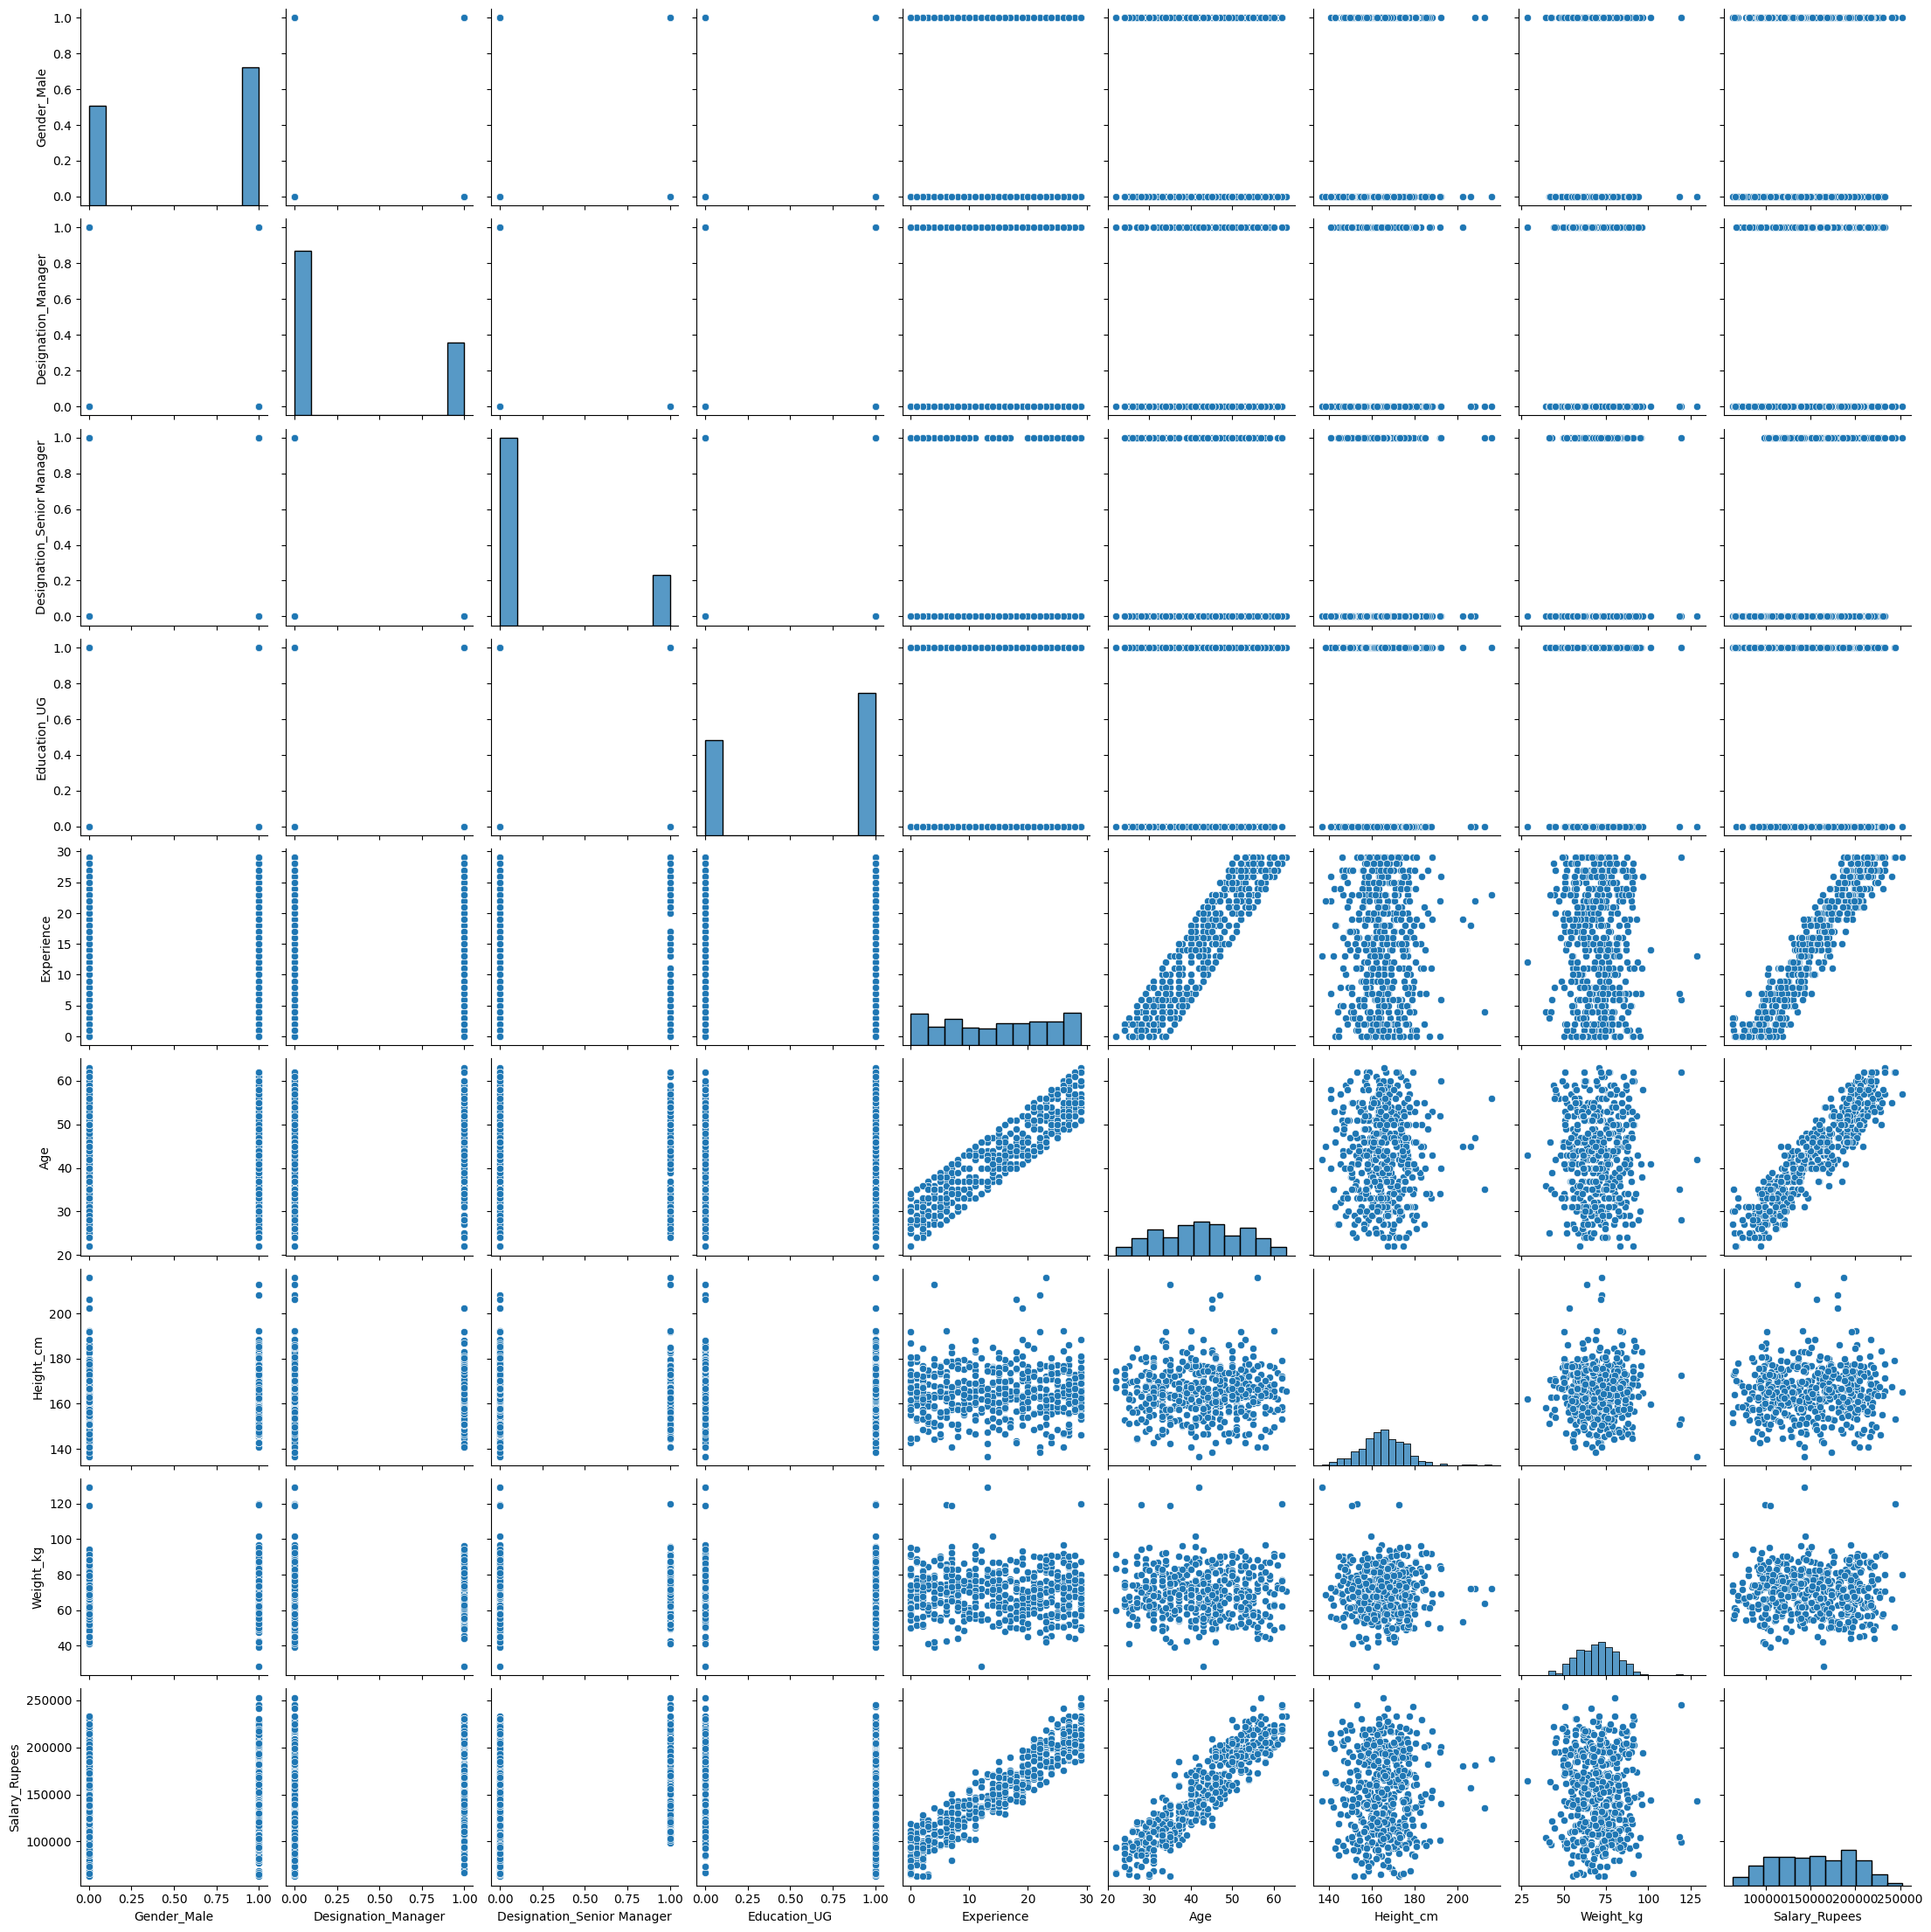

In [ ]:
sns.pairplot(final_data)

In [ ]:
#from the pair plot we see age and exprience have linearity with target variable salary
#where as height and weight  has no linearity with target variable

###### No multicollinearity
Independent variables should not be highly correlated with each other.

We use Variance Inflation Factor (VIF) — it tells how much a variable is linearly dependent on the others.

Check VIF (Variance Inflation Factor)

VIF = (1/1-R2)

| VIF Value       | Interpretation                       |
| --------------- | ------------------------------------ |
| **= 1**         | No correlation with other predictors |
| **1 < VIF < 5** | Moderate correlation (acceptable)    |
| **> 10**        | High multicollinearity (problematic) |


In [ ]:
#we need to calculate vif values
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [ ]:
import statsmodels.api as sm

In [ ]:
x_train.head(1)

,Gender_Male,Designation_Manager,Designation_Senior Manager,Education_UG,Experience,Age,Height_cm,Weight_kg
205,0,1,0,1,3,36,158.9,58.0


In [ ]:
#[expression for looo]
## since in vif is coming from stats library which is old package we need to add the constant manually for the intercept.
# in sklearn we dont need to add but in stats we have to add the constant to x.
xtrain_const=sm.add_constant(x_train)
[variance_inflation_factor(xtrain_const.values,i) for i in range(xtrain_const.shape[1])]

[np.float64(360.10642302517914),
 np.float64(1.0221253281866662),
 np.float64(1.1776533167884287),
 np.float64(1.1542629569256488),
 np.float64(1.0144517589838569),
 np.float64(6.648688036585323),
 np.float64(6.6924082490331305),
 np.float64(1.0091161436509104),
 np.float64(1.0193169742357537)]

In [ ]:
vif_values=pd.DataFrame()
vif_values['variables_names']=xtrain_const.columns
vif_values["vif_values"]=[variance_inflation_factor(xtrain_const.values,i) for i in range(xtrain_const.shape[1])]
vif_values

,variables_names,vif_values
0,const,360.106423
1,Gender_Male,1.022125
2,Designation_Manager,1.177653
3,Designation_Senior Manager,1.154263
4,Education_UG,1.014452
5,Experience,6.648688
6,Age,6.692408
7,Height_cm,1.009116
8,Weight_kg,1.019317


###### Post Model Building Assumptions

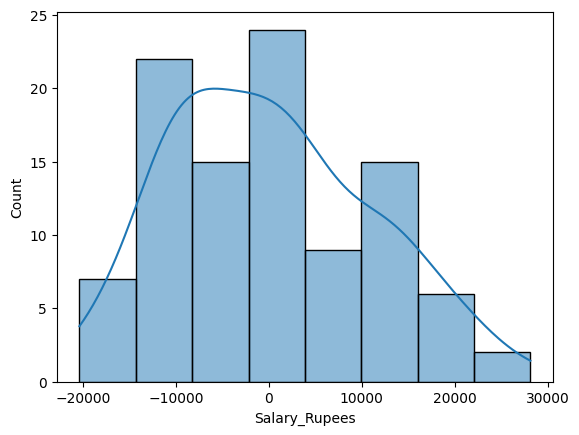

In [ ]:
#we need to find the all the residuals of all the testing data points
#residual=y_actual-y_predict
residual=y_test-y_pred
sns.histplot(residual,kde=True)
plt.show()

###### No Autocorrelation / Independence of errors
Residuals (errors) are independent of each other. No autocorrelation.

Check Durbin–Watson statistic (≈2 means no autocorrelation).

In [ ]:
#Durbin watson test stat stat range is from 0 to 4.
# test_stat < 2 --> Negative autocorrelation
# test_stat = 2 --> No autocorrelation
# test_stat > 2 --> Positive autocorrelation

In [ ]:
from statsmodels.stats.stattools import durbin_watson

In [ ]:
#H0:there is no autocorrelation
#H1: there is autocorrelation
p_val=durbin_watson(residual)
if p_val <= 0.05:
  print(f"since the {p_val} is <=sig_level we reject the null hypothesis we conclude there is autocorrelation")
else:
  print(f"since the {p_val} is >sig_level we fail to reject the null hypothesis we conclude there is no autocorrelation")

since the 1.4733173195631684 is >sig_level we fail to reject the null hypothesis we conclude there is no autocorrelation


###### Normality of residuals

The residuals (errors) are normally distributed (important for inference and hypothesis testing).

Shapiro–Wilk test.

In [ ]:
import scipy.stats as stats
#null:data is normal
#alter:data is not normal
test_stat,p_val=stats.shapiro(residual)
if p_val <= 0.05:
  print(f"since the {p_val} is <=sig_level we reject the null hypothesis we conclude data is not normal")
else:
  print(f"since the {p_val} is > sig-leve we fail to reject the null hypothesis we conclude the data is normal")

since the 0.04935190646680952 is <=sig_level we reject the null hypothesis we conclude data is not normal


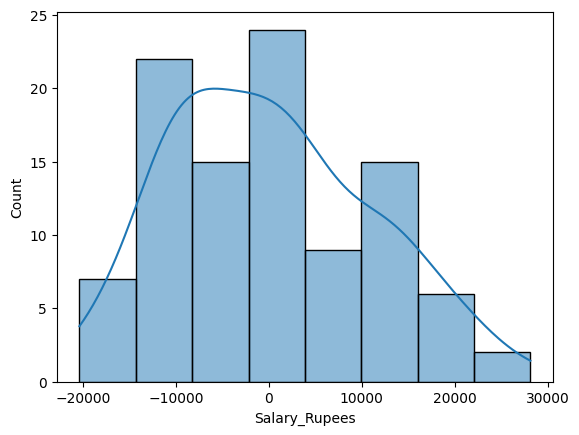

In [ ]:
sns.histplot(residual,kde=True)
plt.show()

###### Homoscedasticity
Constant variance of residuals across all levels of X (errors have equal spread).

Breusch–Pagan Test

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan


In [ ]:
#null:the residual have equal varience
#alter:the residuals not have equal varience
het_breuschpagan(residual,exog_het=sm.add_constant(y_test))
# we will cosnider the 3rd and 4th o/p
p_val = 0.32
if p_val <=0.05:
  print(f"since the {p_val} is <=sig_level we reject the null hypothesis we conclude the residuals have unequal varience")
else:
  print(f"since the {p_val} is > sig-leve we fail to reject the null hypothesis we conclude the residuals have equal varience")


since the 0.32 is > sig-leve we fail to reject the null hypothesis we conclude the residuals have equal varience


##### Regularization

Regularization is a technique used to prevent overfitting in regression or machine learning models by penalizing large coefficients.

 It adds a penalty term to the model’s cost function (loss function), discouraging the model from relying too heavily on any one predictor

In [ ]:
mlr=LinearRegression()
mlr.fit(x_train,y_train)

LinearRegression()

In [ ]:
#now lets pass a same training data to model for predictions
train_predict=mlr.predict(x_train)

###### Train Error

In [ ]:
#train_error=train_actual-train_predict
print("MAPE:",mean_absolute_percentage_error(y_train,train_predict)*100)

MAPE: 5.697098324130616


###### Test Error

In [ ]:
#test_error=y_actual-y_pred
test_pred=mlr.predict(x_test)
print("MAPE:",mean_absolute_percentage_error(y_test,y_pred)*100)

MAPE: 6.026430086594017


###### Variance Error

If error on train is very low and error on test is very high its Variance error and Over Fit Model.

###### Bias Error

If error on train & test  is very low its Bias error and Under Fit Model.

###### Lasso
Lasso regression, also known as L1 regularization, adds a penalty equal to the absolute value of the magnitude of coefficients to the loss function. It can shrink some coefficients exactly to zero, thereby performing variable selection in addition to regularization.

###### Ridge

Ridge regression, also known as L2 regularization, is a technique that adds a penalty equal to the square of the magnitude of coefficients to the loss function. It helps to reduce model complexity and multicollinearity by shrinking the regression coefficients toward zero but never exactly zero.

###### Elastic Net
Elastic Net regression is a combination of L1 (Lasso) and L2 (Ridge) regularization techniques. It adds both penalties to the loss function, balancing coefficient shrinkage and variable selection, making it suitable when predictors are highly correlated.

##### Cross Validation

##### Grid Search

##### Gradient Descent

In [ ]:
x_train.head(1)

,Gender_Male,Designation_Manager,Designation_Senior Manager,Education_UG,Experience,Age,Height_cm,Weight_kg
205,0,1,0,1,3,36,158.9,58.0


In [ ]:
y_train.head(1)

,Salary_Rupees
205,117277.49


In [ ]:
x_test.head(1)

,Gender_Male,Designation_Manager,Designation_Senior Manager,Education_UG,Experience,Age,Height_cm,Weight_kg
69,1,0,0,1,25,51,160.9,76.9


In [ ]:
from sklearn.linear_model import SGDRegressor
sgd=SGDRegressor()
sgd.fit(x_train,y_train)
train_pred=sgd.predict(x_train)
test_pred=sgd.predict(x_test)
print("train error:",mean_absolute_percentage_error(y_train,train_pred))
print("test error:",mean_absolute_percentage_error(y_test,test_pred))

train error: 85473394.01663202
test error: 88616881.70747037


In [ ]:
sgd.intercept_

array([7.26584025e+09])

In [ ]:
sgd.coef_

array([-1.09916905e+11,  5.37478106e+10,  4.84708589e+08, -2.00579472e+11,
        2.59656949e+11,  2.32661766e+10,  1.14603126e+11, -1.53819626e+11])